# Стадия 7. Клинические признаки: пороги, индексы и сплайны

**Данные:** `data/processed/train_model.parquet` (15 признаков модели) и
`data/processed/train_clean.parquet` (сырые показатели до преобразований), оба — результат стадии 1.
**Предыдущие этапы:** `Stage_3_classification.ipynb` — базовая модель;
`Stage_4_polynomial_regularization.ipynb` — полиномы и штрафы;
`Stage_6_pipelines_cv.ipynb` — пайплайны и схемы проверки.

**Цель стадии.** Проверить, добавляют ли качество признаки, которых модель пока не видит:
клинические пороги (границы, знакомые врачу) и медицинские отношения показателей.
Полиномиальные признаки стадии 4 умеют только умножать, но не делить, поэтому отношения
в них не появляются. Отдельно проверяются два технических вопроса: нужен ли `log1p`,
если уже применяется устойчивое масштабирование, и не вредно ли масштабировать бинарные столбцы.

## **1. Импорты и настройки**

In [1]:
# Стандартная библиотека Python
import os
import time
import warnings

# Сторонние библиотеки
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             log_loss, recall_score)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (MinMaxScaler, PolynomialFeatures, RobustScaler,
                                   SplineTransformer, StandardScaler)

pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

# Единое зерно случайности для всего ноутбука: выборки, разбиения, кросс-валидация.
# Значение не меняется между прогонами и стадиями, поэтому результаты сравнимы.
RANDOM_STATE = 42

## **2. Данные: два файла и проверка сопоставимости**

Модель стадий 3–6 работала только с `train_model.parquet`, где скошенные лабораторные
показатели уже переведены в логарифмы. Для клинических порогов нужны **исходные единицы**:
граница «билирубин выше 2.0» имеет смысл в мг/дл, а не в логарифме. Поэтому стадия читает
второй файл — `train_clean.parquet` — и первым делом проверяет, что строки в обоих файлах
идут в одном порядке и описывают одних и тех же пациентов.

In [2]:
# Корень проекта: папка с data/, найденная вверх по дереву от текущей директории
def find_project_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(d, 'data')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError('Папка data/ не найдена вверх по дереву от ' + d)
        d = parent


PROJECT_ROOT = find_project_root()
model = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_model.parquet'))
clean = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_clean.parquet'))

print(f'train_model: {model.shape[0]} строк x {model.shape[1]} столбцов')
print(f'train_clean: {clean.shape[0]} строк x {clean.shape[1]} столбцов')

# Сопоставимость: одинаковое число строк, совпадающая цель, совпадающие log-столбцы
assert model.shape[0] == clean.shape[0], 'Файлы должны описывать одни и те же строки'
assert (model['Status'].values == clean['Status'].values).all(), 'Цель должна совпадать построчно'
for log_col in ['log_Bilirubin', 'log_Copper', 'log_Alk_Phos']:
    raw = log_col.replace('log_', '')
    assert np.allclose(model[log_col], np.log1p(clean[raw])), f'{log_col} не совпадает с log1p({raw})'
print('Файлы сопоставимы: строки, цель и log-столбцы совпадают.')

X_base = model.drop(columns=['Status']).astype(float)
y = model['Status'].astype(str)
assert X_base.shape[1] == 15, 'В матрице модели должно быть 15 признаков'
print(f'\nБазовая матрица: {X_base.shape[0]} строк x {X_base.shape[1]} признаков')
print('Признаки:', ', '.join(X_base.columns))

train_model: 7905 строк x 16 столбцов
train_clean: 7905 строк x 34 столбцов
Файлы сопоставимы: строки, цель и log-столбцы совпадают.

Базовая матрица: 7905 строк x 15 признаков
Признаки: log_Bilirubin, log_Copper, log_Alk_Phos, log_SGOT, log_Cholesterol, log_Tryglicerides, Albumin, Platelets, Prothrombin, Age_years, Stage, Edema_num, Sex_M, Hepatomegaly_Y, Spiders_Y


### Что даёт второй файл

`train_model.parquet` — это уже **результат** решений стадии 1: отобранные 15 столбцов,
часть из них в логарифмах. `train_clean.parquet` содержит те же строки, но в исходных
единицах измерения, плюс столбцы, которые в модель не вошли.

Такое разделение удобно: новые признаки строятся из сырых значений, а базовые 15 столбцов
берутся в том виде, в котором их уже проверяли стадии 3–6. Пересчитывать логарифмы заново
не нужно — иначе появился бы риск незаметно разойтись с прежними результатами.

## **3. Клинические пороги и медицинские индексы**

Линейная модель складывает показатели с постоянным весом: каждое дополнительное значение
билирубина меняет оценку одинаково. В клинике это не так — существует граница, за которой
показатель меняет смысл. Шкала Чайлда — Пью, которой оценивают тяжесть цирроза, устроена
именно как набор порогов. Проверим, помогает ли модели знать эти границы явно.

Индексы решают другую задачу. Полиномиальные признаки дают произведения и квадраты,
но **не дают отношений**: `A × B` появляется, а `A / B` — нет. Между тем в медицине
диагностическую ценность несут именно отношения показателей.

In [3]:
# Пороги взяты из клинической практики (шкала Чайлда — Пью и общие нормы лаборатории).
# Каждый порог превращается в бинарный столбец: 1 — значение перешло границу, 0 — нет.
thresholds = pd.DataFrame({
    'bili_gt_2':   (clean['Bilirubin'] > 2.0).astype(float),
    'bili_gt_3':   (clean['Bilirubin'] > 3.0).astype(float),
    'alb_lt_3_5':  (clean['Albumin'] < 3.5).astype(float),
    'alb_lt_2_8':  (clean['Albumin'] < 2.8).astype(float),
    'pt_gt_12':    (clean['Prothrombin'] > 12.0).astype(float),
    'plt_lt_150':  (clean['Platelets'] < 150).astype(float),
})

DESCRIPTIONS = {
    'bili_gt_2': 'билирубин выше 2.0 мг/дл — выраженная желтуха',
    'bili_gt_3': 'билирубин выше 3.0 мг/дл — тяжёлая желтуха',
    'alb_lt_3_5': 'альбумин ниже 3.5 г/дл — гипоальбуминемия',
    'alb_lt_2_8': 'альбумин ниже 2.8 г/дл — тяжёлая гипоальбуминемия',
    'pt_gt_12': 'протромбиновое время выше 12 с — нарушение свёртывания',
    'plt_lt_150': 'тромбоциты ниже 150 — тромбоцитопения',
}

table = pd.DataFrame({
    'порог': list(thresholds.columns),
    'что означает': [DESCRIPTIONS[c] for c in thresholds.columns],
    'доля единиц': [thresholds[c].mean() for c in thresholds.columns],
    'строк': [int(thresholds[c].sum()) for c in thresholds.columns],
})
display(table.round(4).set_index('порог'))

# Порог-константа бесполезен: если единиц почти нет или почти все — столбец не разделяет строки
assert thresholds.nunique().min() == 2, 'У каждого порога должны быть оба значения'
assert thresholds.mean().between(0.02, 0.98).all(), 'Порог не должен быть почти константой'
print('У всех порогов есть оба значения, ни один не является почти константой.')

,что означает,доля единиц,строк
порог,,,
bili_gt_2,билирубин выше 2.0 мг/дл — выраженная желтуха,0.3171,2507
bili_gt_3,билирубин выше 3.0 мг/дл — тяжёлая желтуха,0.2440,1929
alb_lt_3_5,альбумин ниже 3.5 г/дл — гипоальбуминемия,0.3763,2975
alb_lt_2_8,альбумин ниже 2.8 г/дл — тяжёлая гипоальбуминемия,0.0306,242
pt_gt_12,протромбиновое время выше 12 с — нарушение свё...,0.0431,341
plt_lt_150,тромбоциты ниже 150 — тромбоцитопения,0.0886,700


У всех порогов есть оба значения, ни один не является почти константой.


### Пороги: почему именно эти границы

Билирубин 2.0 и 3.0 мг/дл — ступени шкалы Чайлда — Пью: до 2 баллов состояние считается
компенсированным, выше — декомпенсированным. Альбумин 3.5 г/дл — нижняя граница нормы,
2.8 г/дл — выраженная гипоальбуминемия. Протромбиновое время 12 с — верхняя граница нормы,
дальше начинается нарушение свёртывания. Тромбоциты 150 — общепринятая граница
тромбоцитопении, которая при циррозе отражает портальную гипертензию.

Важно, что все шесть порогов дают заметные доли: от 3.1 % (альбумин ниже 2.8) до 37.6 %
(альбумин ниже 3.5). Порог-константа ничего не добавил бы модели.

In [4]:
# Медицинские отношения. Деление на ноль невозможно: минимальные значения проверены ниже.
apri_raw = (clean['SGOT'] / 40.0) / clean['Platelets'] * 100.0
bili_alb_raw = clean['Bilirubin'] / clean['Albumin']
age_plt_raw = clean['Age_years'] / clean['Platelets']

indices = pd.DataFrame({
    'log_APRI': np.log1p(apri_raw),
    'log_bili_alb': np.log1p(bili_alb_raw),
    'log_age_plt': np.log1p(age_plt_raw),
})

print('Минимальные значения знаменателей:')
print(f"  Platelets = {clean['Platelets'].min():.1f}, Albumin = {clean['Albumin'].min():.2f}")
print(f"  inf в индексах: {int(np.isinf(indices.values).sum())}, "
      f"пропусков: {int(indices.isna().sum().sum())}")
assert np.isfinite(indices.values).all(), 'В индексах не должно быть бесконечностей и пропусков'

summary = indices.describe().T[['min', '50%', 'max']]
summary['асимметрия до log'] = [apri_raw.skew(), bili_alb_raw.skew(), age_plt_raw.skew()]
summary['асимметрия после log'] = [indices[c].skew() for c in indices.columns]
print('\nРаспределение индексов (после log1p):')
display(summary.round(4))

print('\nМедиана индекса по классам исхода:')
by_class = indices.assign(Status=y.values).groupby('Status').median().T
display(by_class.round(4))

Минимальные значения знаменателей:
  Platelets = 62.0, Albumin = 1.96
  inf в индексах: 0, пропусков: 0

Распределение индексов (после log1p):


,min,50%,max,асимметрия до log,асимметрия после log
log_APRI,0.1712,0.7016,2.6830,3.3862,1.0970
log_bili_alb,0.0660,0.2635,2.3850,3.4353,1.9651
log_age_plt,0.0495,0.1751,0.7557,2.4413,1.8745



Медиана индекса по классам исхода:


Status,C,CL,D
log_APRI,0.6313,0.7462,0.8764
log_bili_alb,0.2059,0.5719,0.6399
log_age_plt,0.1656,0.1456,0.2036


### Индексы: что они измеряют

**APRI** (индекс отношения AST к тромбоцитам) — один из стандартных неинвазивных маркеров
фиброза печени. Считается как `(AST / 40) / тромбоциты × 100`; значения выше 1.0 говорят
о значимом фиброзе, выше 2.0 — о циррозе. Логарифм нужен потому, что распределение индекса
сильно скошено вправо: большинство значений около единицы, но встречаются и 13.6.

**Билирубин к альбумину** отражает баланс между токсической нагрузкой (билирубин)
и синтетической функцией печени (альбумин). Высокое значение означает, что печень
не справляется сразу по двум направлениям.

**Возраст к тромбоцитам** — косвенная мера того, насколько состояние пациента
соответствует его возрасту. Класс `CL` (трансплантация) устроен так, что пожилым пациентам
пересадку делают реже, поэтому отношение возраста к тромбоцитам может отделять этот класс
лучше, чем каждый показатель по отдельности.

Логарифм применён ко всем трём отношениям, потому что исходные распределения имеют
асимметрию от 2.4 до 3.4. После `log1p` она падает — это видно в таблице выше.

### Вывод по новым признакам

Девять новых признаков построены, семь из них вошли в итоговый набор. Ни один не является константой: доли единиц
у порогов лежат от 3.1 % (альбумин ниже 2.8) до 37.6 % (альбумин ниже 3.5).
Бесконечностей и пропусков в отношениях нет — минимальный знаменатель 62.0 у тромбоцитов
и 1.96 у альбумина, деление всегда корректно.

Логарифм действительно выпрямляет отношения: асимметрия APRI падает с 3.39 до 1.10,
отношения «билирубин к альбумину» — с 3.44 до 1.97, «возраст к тромбоцитам» — с 2.44 до 1.87.

Новые признаки разделяют классы. Медиана отношения «билирубин к альбумину» у класса `CL`
(0.5719) в 2.8 раза выше, чем у `C` (0.2059), и близка к медиане `D` (0.6399) — то есть
этот индекс показывает тяжесть состояния, но не отличает трансплантацию от смерти.
Индекс APRI ведёт себя так же: 0.6313 у `C`, 0.7462 у `CL`, 0.8764 у `D`.
Отношение «возраст к тромбоцитам», наоборот, у `CL` **ниже** (0.1456), чем у `C` (0.1656) —
это согласуется с тем, что трансплантацию чаще получают более молодые пациенты.

## **4. Сравнение наборов признаков**

Главный вопрос стадии: дают ли новые признаки прирост, и если да, то какие из них.
Признаки добавляются **малыми группами по два-три**, а не все сразу. Причина арифметическая:
полином второй степени от `N` признаков даёт около `N²/2` столбцов, поэтому добавление
семи признаков разом превращает матрицу из 135 столбцов в 275. Если качество при этом
не растёт, невозможно понять, какой именно признак виноват.

Схема проверки одна для всех наборов: `StratifiedKFold` на пять блоков с тем же зерном,
что в стадии 6. Модели тоже фиксированы — базовая логистическая регрессия стадии 3
и полином 2-й степени с L1-штрафом `C = 0.1` из стадии 4. Гиперпараметры не подбираются
заново: иначе различие между наборами смешалось бы с различием между удачными подборами.

In [5]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Группы новых признаков — в том порядке, в котором они добавляются
GROUP_RELATIONS = ['log_bili_alb', 'log_age_plt']
GROUP_FLAGS_MAIN = ['bili_gt_2', 'alb_lt_3_5']
GROUP_APRI = ['log_APRI']
GROUP_FLAGS_EXTRA = ['plt_lt_150', 'pt_gt_12']

X_new = pd.concat([thresholds[GROUP_FLAGS_MAIN + GROUP_FLAGS_EXTRA],
                   indices[GROUP_RELATIONS + GROUP_APRI]], axis=1)
assert list(X_new.columns) == (GROUP_FLAGS_MAIN + GROUP_FLAGS_EXTRA
                               + GROUP_RELATIONS + GROUP_APRI)
print(f'Новых признаков: {X_new.shape[1]}')
print(list(X_new.columns))

# Бинарные столбцы масштабировать не нужно: они уже приведены к 0/1.
# Для них в ColumnTransformer оставлен passthrough, остальные проходят через RobustScaler.
BINARY_COLS = ['Sex_M', 'Hepatomegaly_Y', 'Spiders_Y'] + GROUP_FLAGS_MAIN + GROUP_FLAGS_EXTRA
print(f'\nБинарных столбцов: {len(BINARY_COLS)}')


def make_prep(X_columns, scaler):
    # Бинарные столбцы пропускаются как есть, числовые масштабируются выбранным способом.
    binaries = [c for c in X_columns if c in BINARY_COLS]
    numeric = [c for c in X_columns if c not in BINARY_COLS]
    return ColumnTransformer([('bin', 'passthrough', binaries),
                              ('num', scaler, numeric)])


def linear_pipeline(X_columns, scaler=RobustScaler()):
    # Модель стадии 3: логистическая регрессия на исходных признаках.
    return Pipeline([('prep', make_prep(X_columns, scaler)),
                     ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])


def poly_pipeline(X_columns, scaler=RobustScaler(), c_value=0.1):
    # Модель стадии 4: полином второй степени и L1-штраф.
    return Pipeline([('prep', make_prep(X_columns, scaler)),
                     ('poly', PolynomialFeatures(degree=2, include_bias=False)),
                     ('model', LogisticRegression(solver='saga', l1_ratio=1.0, C=c_value,
                                                  max_iter=5000, tol=1e-3,
                                                  random_state=RANDOM_STATE))])


def cv_loss(pipeline, X_train, y_train):
    # Средняя лог-потеря и её разброс по пяти блокам.
    scores = cross_val_score(pipeline, X_train, y_train, cv=CV,
                             scoring='neg_log_loss', n_jobs=-1)
    return -scores.mean(), scores.std(), -scores

Новых признаков: 7
['bili_gt_2', 'alb_lt_3_5', 'plt_lt_150', 'pt_gt_12', 'log_bili_alb', 'log_age_plt', 'log_APRI']

Бинарных столбцов: 7


In [6]:
FEATURE_SETS = [
    ('15 базовых', [X_base]),
    ('+2 отношения (17)', [X_base, X_new[GROUP_RELATIONS]]),
    ('+2 флага (19)', [X_base, X_new[GROUP_RELATIONS + GROUP_FLAGS_MAIN]]),
    ('+APRI (20)', [X_base, X_new[GROUP_RELATIONS + GROUP_FLAGS_MAIN + GROUP_APRI]]),
    ('+2 флага (22)', [X_base, X_new[GROUP_RELATIONS + GROUP_FLAGS_MAIN
                                  + GROUP_APRI + GROUP_FLAGS_EXTRA]]),
]

rows = []
fold_losses = {}
started = time.time()
for name, parts in FEATURE_SETS:
    X_set = pd.concat(parts, axis=1)
    X_tr, _, y_tr, _ = train_test_split(X_set, y, test_size=0.25, stratify=y,
                                        random_state=RANDOM_STATE)
    lin = linear_pipeline(list(X_set.columns))
    poly = poly_pipeline(list(X_set.columns))
    lin_mean, lin_std, lin_folds = cv_loss(lin, X_tr, y_tr)
    poly_mean, poly_std, poly_folds = cv_loss(poly, X_tr, y_tr)
    poly.fit(X_tr, y_tr)
    n_columns = poly[:-1].transform(X_tr.head(2)).shape[1]
    n_zero = int(np.sum(np.abs(poly[-1].coef_) < 1e-8))
    rows.append({
        'набор': name,
        'признаков': X_set.shape[1],
        'столбцов полинома': n_columns,
        'лог-потеря линейной': lin_mean,
        'разброс линейной': lin_std,
        'лог-потеря полинома': poly_mean,
        'разброс полинома': poly_std,
        'обнулено': f'{n_zero} из {poly[-1].coef_.size}',
    })
    fold_losses[name] = {'линейная': lin_folds, 'полином': poly_folds}

ablation = pd.DataFrame(rows).set_index('набор')
display(ablation.round(4))
print(f'Все прогоны: {time.time() - started:.0f} с')

base_poly = ablation.loc['15 базовых', 'лог-потеря полинома']
base_lin = ablation.loc['15 базовых', 'лог-потеря линейной']
print(f'\nЛучший набор по линейной модели: '
      f'{ablation["лог-потеря линейной"].idxmin()} '
      f'({ablation["лог-потеря линейной"].min():.4f})')
print(f'Лучший набор по полиному: '
      f'{ablation["лог-потеря полинома"].idxmin()} '
      f'({ablation["лог-потеря полинома"].min():.4f})')
print(f'Выигрыш лучшего набора: линейная {base_lin - ablation["лог-потеря линейной"].min():.4f}, '
      f'полином {base_poly - ablation["лог-потеря полинома"].min():.4f}')

,признаков,столбцов полинома,лог-потеря линейной,разброс линейной,лог-потеря полинома,разброс полинома,обнулено
набор,,,,,,,
15 базовых,15,135,0.5132,0.0174,0.4982,0.0170,291 из 405
+2 отношения (17),17,170,0.5067,0.0172,0.4973,0.0176,380 из 510
+2 флага (19),19,209,0.5065,0.0169,0.4972,0.0174,496 из 627
+APRI (20),20,230,0.5065,0.0176,0.4972,0.0174,545 из 690
+2 флага (22),22,275,0.5064,0.0170,0.4968,0.0173,681 из 825


Все прогоны: 49 с

Лучший набор по линейной модели: +2 флага (22) (0.5064)
Лучший набор по полиному: +2 флага (22) (0.4968)
Выигрыш лучшего набора: линейная 0.0067, полином 0.0013


### Вывод по наборам признаков

| Набор | Признаков | Столбцов полинома | Линейная модель | Полином + L1 |
|---|---|---|---|---|
| 15 базовых | 15 | 135 | 0.5132 ± 0.0174 | 0.4982 ± 0.0170 |
| +2 отношения | 17 | 170 | **0.5067** ± 0.0172 | 0.4973 ± 0.0176 |
| +2 флага | 19 | 209 | 0.5065 ± 0.0169 | 0.4972 ± 0.0174 |
| +APRI | 20 | 230 | 0.5065 ± 0.0176 | 0.4972 ± 0.0174 |
| +2 флага | 22 | 275 | 0.5064 ± 0.0170 | **0.4968** ± 0.0173 |

**Отношения — самый ценный вклад.** Одна эта пара признаков даёт линейной модели
улучшение на **0.0065** (0.5132 → 0.5067), а все остальные пять признаков вместе
добавляют лишь **0.0003**. Причина понятна: полиномиальные признаки строят произведения,
но отношений не создают, поэтому деление приходится добавлять вручную.

**Для полиномиальной модели прирост почти отсутствует.** 0.4982 → 0.4968, то есть
**0.0013** — это меньше разброса между блоками (0.0173) и намного меньше разброса
между двадцатью разбиениями из стадии 6 (0.0458). Полином второй степени уже содержит
произведения показателей, поэтому ручные отношения и пороги почти ничего не добавляют:
модель находит похожие комбинации сама.

**Столбцы растут быстрее, чем качество.** Переход с 15 на 22 признака увеличивает
полиномиальную матрицу со 135 до 275 столбцов — вдвое, — а лог-потеря улучшается
на 0.0013. L1-штраф при этом обнуляет 681 коэффициент из 825, то есть модель отбрасывает
большую часть новой сложности.

Практический вывод: для линейной модели клинические признаки стоит добавить, для
полиномиальной — они почти бесполезны. Обе модели дальше строятся на полном наборе
из 22 признаков, потому что вреда он не приносит, а линейный вариант без него заметно слабее.

## **5. Проверка логарифмирования при устойчивом масштабировании**

Логарифмы появились на стадии 1, когда данные ещё не масштабировались. С тех пор
в пайплайн пришёл `RobustScaler`, который сам по себе гасит влияние выбросов: он вычитает
медиану и делит на межквартильный размах, то есть смотрит на середину распределения,
а не на край. Возникает законный вопрос: не стала ли логарифмическая ступень лишней?

Проверяем строго: тот же пайплайн, та же схема проверки, единственное отличие —
шесть скошенных показателей берутся либо в логарифме, либо в исходных единицах.

In [7]:
LOG_TO_RAW = {'log_Bilirubin': 'Bilirubin', 'log_Copper': 'Copper',
              'log_Alk_Phos': 'Alk_Phos', 'log_SGOT': 'SGOT',
              'log_Cholesterol': 'Cholesterol', 'log_Tryglicerides': 'Tryglicerides'}

X_22 = pd.concat([X_base, X_new], axis=1)


def with_raw_scales(X_source):
    # Заменяет log-столбцы на исходные показатели из train_clean.
    X_out = X_source.drop(columns=list(LOG_TO_RAW)).copy()
    for log_col, raw_col in LOG_TO_RAW.items():
        X_out[raw_col] = clean[raw_col].astype(float)
    return X_out


variants = {
    'log1p + RobustScaler': X_22,
    'исходные значения + RobustScaler': with_raw_scales(X_22),
}

log_rows = []
for name, X_set in variants.items():
    X_tr, _, y_tr, _ = train_test_split(X_set, y, test_size=0.25, stratify=y,
                                        random_state=RANDOM_STATE)
    mean, std, folds = cv_loss(poly_pipeline(list(X_set.columns)), X_tr, y_tr)
    log_rows.append({'вариант': name, 'лог-потеря': mean, 'разброс': std})

log_table = pd.DataFrame(log_rows).set_index('вариант')
display(log_table.round(4))
difference = (log_table.loc['исходные значения + RobustScaler', 'лог-потеря']
              - log_table.loc['log1p + RobustScaler', 'лог-потеря'])
print(f'Разница (исходные минус log1p): {difference:+.4f}')
print('Положительная разница означает, что логарифм помогает даже после RobustScaler.')

,лог-потеря,разброс
вариант,,
log1p + RobustScaler,0.4968,0.0173
исходные значения + RobustScaler,0.5057,0.0186


Разница (исходные минус log1p): +0.0089
Положительная разница означает, что логарифм помогает даже после RobustScaler.


### Вывод по логарифмированию

Логарифм остаётся полезным и после перехода на устойчивое масштабирование:

| Вариант | Лог-потеря | Разброс |
|---|---|---|
| `log1p` + `RobustScaler` | **0.4968** | 0.0173 |
| Исходные значения + `RobustScaler` | 0.5057 | 0.0186 |

Разница **0.0089** в пользу логарифма — почти в семь раз больше, чем прирост
полиномиальной модели от всех клинических признаков вместе (0.0013). Гипотеза «`RobustScaler` уже гасит выбросы, поэтому логарифм
лишний» **не подтвердилась**.

Причина в том, что два преобразования решают разные задачи. `RobustScaler` приводит
столбцы к одному масштабу, но **не меняет форму зависимости**: если показатель растёт
экспоненциально, после масштабирования он растёт так же. Логарифм выпрямляет саму кривую,
и только после этого линейная комбинация признаков начинает работать.

Обратите внимание: у варианта с исходными значениями выше и разброс (0.0186 против 0.0173) —
без логарифма оценка менее устойчива. Логарифмическая ступень стадии 1 сохраняется.

## **6. Бинарные признаки: масштабировать или пропускать**

`RobustScaler` вычитает медиану и делит на межквартильный размах. Для столбца из нулей
и единиц это работает странно: если единиц меньше четверти, то и медиана, и оба квартиля
равны нулю, размах получается нулевым, и scikit-learn подставляет единицу вместо деления
на ноль. В итоге столбец остаётся в исходном виде, но проходит через преобразование,
смысла в котором нет.

Проверяем, есть ли разница: сначала все столбцы идут через масштабирование, затем
бинарные пропускаются через `passthrough`.

In [8]:
binary_check = []
for c in BINARY_COLS:
    q1, q3 = np.percentile(X_22[c], [25, 75])
    binary_check.append({'столбец': c, 'медиана': np.median(X_22[c]),
                         'межквартильный размах': q3 - q1, 'доля единиц': X_22[c].mean()})
display(pd.DataFrame(binary_check).set_index('столбец').round(4))

X_tr, _, y_tr, _ = train_test_split(X_22, y, test_size=0.25, stratify=y,
                                    random_state=RANDOM_STATE)
numeric_only = [c for c in X_22.columns if c not in BINARY_COLS]

all_scaled = Pipeline([
    ('sc', RobustScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LogisticRegression(solver='saga', l1_ratio=1.0, C=0.1, max_iter=5000,
                                 tol=1e-3, random_state=RANDOM_STATE)),
])
binary_passthrough = poly_pipeline(list(X_22.columns))

for tag, pipe in [('все столбцы масштабируются', all_scaled),
                  ('бинарные через passthrough', binary_passthrough)]:
    mean, std, _ = cv_loss(pipe, X_tr, y_tr)
    print(f'{tag:30} лог-потеря {mean:.4f} ± {std:.4f}')

,медиана,межквартильный размах,доля единиц
столбец,,,
Sex_M,0.0,0.0,0.0720
Hepatomegaly_Y,1.0,1.0,0.5113
Spiders_Y,0.0,0.0,0.2453
bili_gt_2,0.0,1.0,0.3171
alb_lt_3_5,0.0,1.0,0.3763
plt_lt_150,0.0,0.0,0.0886
pt_gt_12,0.0,0.0,0.0431


все столбцы масштабируются     лог-потеря 0.4967 ± 0.0170


бинарные через passthrough     лог-потеря 0.4968 ± 0.0173


### Вывод по бинарным столбцам

Разницы практически нет: 0.4967 против 0.4968, то есть **0.0001** — на два порядка меньше
разброса между блоками. На этих данных `RobustScaler` безвреден для бинарных столбцов,
хотя и бесполезен.

Проверка межквартильного размаха объясняет, почему: у четырёх из семи бинарных столбцов
размах равен нулю — `Sex_M` (7.2 % единиц), `Spiders_Y` (24.5 %), `plt_lt_150` (8.9 %),
`pt_gt_12` (4.3 %). В этих случаях scikit-learn подставляет единицу вместо деления на ноль,
и столбец фактически остаётся в исходном виде. У остальных трёх размах равен единице,
и после вычитания медианы столбец превращается в тот же 0/1 со сдвигом.

Тем не менее `passthrough` оставлен в пайплайне: он не улучшает метрику, но делает
поведение предсказуемым. Если доля единиц в бинарном столбце изменится при появлении новых
данных, масштабирование начнёт незаметно менять его значения — а пропуск через `passthrough`
такой возможности не даёт.

## **7. Сравнение способов масштабирования (пункт со звёздочкой)**

Пункт со звездой из критериев: проверить на одной схеме проверки разные способы
масштабирования и вариант без него, и посмотреть не только на метрику, но и на коэффициенты.

Сравниваются четыре варианта: без масштабирования, `StandardScaler` (вычитает среднее,
делит на стандартное отклонение), `MinMaxScaler` (сжимает в отрезок от 0 до 1),
`RobustScaler` (вычитает медиану, делит на межквартильный размах).

Для полиномиальной модели с L1-штрафом масштаб имеет прямое значение: штраф одинаков
для всех коэффициентов, поэтому плохо масштабированный столбец получает либо неоправданно
маленький вес, либо неоправданно большой. Число обнулённых коэффициентов показывает,
насколько охотно модель отбрасывает столбцы при данном масштабе.

In [9]:
SCALERS = [
    ('без масштабирования', 'passthrough'),
    ('StandardScaler', StandardScaler()),
    ('MinMaxScaler', MinMaxScaler()),
    ('RobustScaler', RobustScaler()),
]

X_tr, _, y_tr, _ = train_test_split(X_22, y, test_size=0.25, stratify=y,
                                    random_state=RANDOM_STATE)
scaling_rows = []
for name, scaler in SCALERS:
    lin = linear_pipeline(list(X_22.columns), scaler=scaler)
    poly = poly_pipeline(list(X_22.columns), scaler=scaler)
    # Предупреждения о сходимости не печатаем: сходимость проверяется явно по n_iter_
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lin_mean, lin_std, _ = cv_loss(lin, X_tr, y_tr)
        poly_mean, poly_std, _ = cv_loss(poly, X_tr, y_tr)
        lin.fit(X_tr, y_tr)
        poly.fit(X_tr, y_tr)

    lin_coef = lin[-1].coef_
    poly_coef = poly[-1].coef_
    lin_iter = int(lin[-1].n_iter_[0])
    scaling_rows.append({
        'масштабирование': name,
        'лог-потеря линейной': lin_mean,
        'разброс': lin_std,
        'лог-потеря полинома': poly_mean,
        'разброс ': poly_std,
        'итераций линейной': lin_iter,
        'сошлась': lin_iter < 2000,
        'обнулено полинома': int(np.sum(np.abs(poly_coef) < 1e-8)),
        'всего коэффициентов': poly_coef.size,
        'макс |коэф.| линейной': float(np.abs(lin_coef).max()),
        'макс |коэф.| полинома': float(np.abs(poly_coef).max()),
        'средний |коэф.| полинома': float(np.abs(poly_coef).mean()),
    })

scaling = pd.DataFrame(scaling_rows).set_index('масштабирование')
display(scaling.round(4))

best_scaler = scaling['лог-потеря полинома'].idxmin()
print(f'\nЛучший вариант для полинома: {best_scaler} '
      f'({scaling.loc[best_scaler, "лог-потеря полинома"]:.4f})')
print(f'Худший вариант: {scaling["лог-потеря полинома"].idxmax()} '
      f'({scaling["лог-потеря полинома"].max():.4f})')
print(f'Разброс между способами: '
      f'{scaling["лог-потеря полинома"].max() - scaling["лог-потеря полинома"].min():.4f}')
print('\nСходимость линейной модели за 2000 итераций:')
for name in scaling.index:
    mark = 'да' if scaling.loc[name, 'сошлась'] else 'нет'
    print(f'  {name:22} {mark:3} ({int(scaling.loc[name, "итераций линейной"])} итераций)')

,лог-потеря линейной,разброс,лог-потеря полинома,разброс,итераций линейной,сошлась,обнулено полинома,всего коэффициентов,макс |коэф.| линейной,макс |коэф.| полинома,средний |коэф.| полинома
масштабирование,,,,,,,,,,,
без масштабирования,0.5111,0.0166,0.5868,0.0063,2000,False,96,825,2.6135,0.0010,0.0000
StandardScaler,0.5063,0.0170,0.4969,0.0176,72,True,609,825,1.6739,0.5773,0.0159
MinMaxScaler,0.5089,0.0162,0.5180,0.0156,63,True,774,825,2.9832,3.2329,0.0218
RobustScaler,0.5064,0.0170,0.4968,0.0173,76,True,681,825,1.9824,0.8155,0.0180



Лучший вариант для полинома: RobustScaler (0.4968)
Худший вариант: без масштабирования (0.5868)
Разброс между способами: 0.0900

Сходимость линейной модели за 2000 итераций:
  без масштабирования    нет (2000 итераций)
  StandardScaler         да  (72 итераций)
  MinMaxScaler           да  (63 итераций)
  RobustScaler           да  (76 итераций)


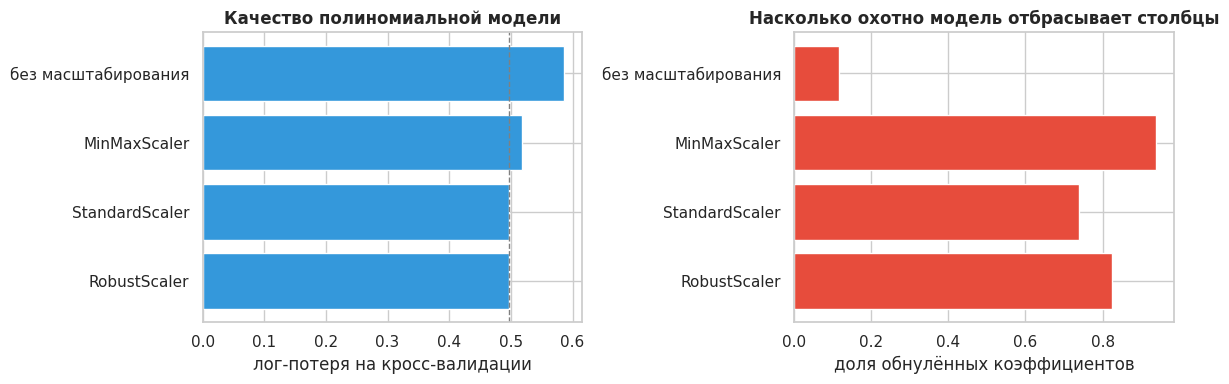

In [10]:
# Наглядное сравнение: метрика и доля обнулённых коэффициентов
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

order = scaling['лог-потеря полинома'].sort_values().index
axes[0].barh(order, scaling.loc[order, 'лог-потеря полинома'], color='#3498db')
axes[0].set_xlabel('лог-потеря на кросс-валидации')
axes[0].set_title('Качество полиномиальной модели', fontweight='bold')
axes[0].axvline(scaling['лог-потеря полинома'].min(), color='grey', ls='--', lw=1)

zero_share = scaling['обнулено полинома'] / scaling['всего коэффициентов']
axes[1].barh(order, zero_share.loc[order], color='#e74c3c')
axes[1].set_xlabel('доля обнулённых коэффициентов')
axes[1].set_title('Насколько охотно модель отбрасывает столбцы', fontweight='bold')

fig.tight_layout()
plt.show()

### Вывод по масштабированию

| Способ | Линейная | Полином + L1 | Обнулено | Макс \|коэф.\| линейной | Макс \|коэф.\| полинома |
|---|---|---|---|---|---|
| без масштабирования | 0.5111 | 0.5868 | 96 из 825 | 2.61 | 0.0010 |
| `StandardScaler` | 0.5063 | 0.4969 | 609 из 825 | 1.67 | 0.5773 |
| `MinMaxScaler` | 0.5089 | 0.5180 | 774 из 825 | 2.98 | 3.2329 |
| `RobustScaler` | **0.5064** | **0.4968** | 681 из 825 | 1.98 | 0.8155 |

**Без масштабирования полиномиальная модель разваливается.** Лог-потеря 0.5868 против
0.4968 у лучшего варианта — разница **0.0900**, в двадцать раз больше, чем прирост
от клинических признаков. Причина видна по коэффициентам: максимальный коэффициент
составляет 0.0010, средний — практически ноль. Признаки измеряются в тысячах
(щелочная фосфатаза доходит до 13 862), их произведения — в миллионах, поэтому
коэффициенты вынужденно сжимаются до тысячных. Такие числа невозможно ни интерпретировать,
ни сравнить между собой: они отражают единицы измерения, а не важность признака.
Вдобавок линейная модель в этом варианте **не сходится** за 2000 итераций, тогда как
с любым масштабированием ей хватает 63–76 итераций: разница в тридцать раз.

**`MinMaxScaler` — второй по неудачности.** Лог-потеря 0.5180, обнулено 774 коэффициента
из 825 — почти все. Сжатие в отрезок от 0 до 1 опирается на минимум и максимум, а значит,
само зависит от крайних значений: один выброс растягивает диапазон и обесценивает
все остальные значения. Максимальный коэффициент при этом вырастает до 3.23 — модель
компенсирует сжатие размахом весов.

**`StandardScaler` и `RobustScaler` практически равны** (0.4969 и 0.4968) и оба хороши.
Различие в устойчивости: `StandardScaler` считает среднее и стандартное отклонение,
которые чувствительны к выбросам, а `RobustScaler` — медиану и межквартильный размах,
которые к ним устойчивы. При появлении новых пациентов с экстремальными анализами
поведение `RobustScaler` изменится меньше.

**Выбран `RobustScaler`.** Он даёт лучшую лог-потеря среди удачных вариантов и не
опирается на крайние значения. Коэффициентов он обнуляет больше, чем `StandardScaler`
(681 против 609 из 825), то есть модель получается разреженнее — для интерпретации это
скорее плюс: меньше столбцов остаётся в работе. Величины коэффициентов при нём имеют
сопоставимый порядок (средний 0.0180), то есть поддаются сравнению между собой.

## **8. Сплайны вместо полинома**

Полином второй степени строит одну гладкую кривую на весь диапазон значений. На краях
диапазона такой полином ведёт себя неустойчиво: небольшое изменение входа даёт большой
скачок выхода. Сплайны устроены иначе — диапазон разбивается на отрезки, и на каждом
строится свой низкостепенный многочлен, состыкованный с соседями. Получается кусочно-гладкая
кривая без взрыва на краях.

`SplineTransformer` из scikit-learn делает это внутри пайплайна: на вход один столбец,
на выходе несколько базисных функций. Проверяем, выигрывает ли такая замена у полинома
на ключевых клинических показателях.

In [11]:
SPLINE_COLUMNS = ['log_Bilirubin', 'Albumin', 'Prothrombin', 'Age_years']
spline_numeric = [c for c in SPLINE_COLUMNS if c in X_22.columns]
other_numeric = [c for c in X_22.columns
                 if c not in BINARY_COLS and c not in spline_numeric]
binary_columns = [c for c in X_22.columns if c in BINARY_COLS]

spline_pipeline = Pipeline([
    ('prep', ColumnTransformer([
        ('bin', 'passthrough', binary_columns),
        ('spl', SplineTransformer(n_knots=4, degree=2, include_bias=False), spline_numeric),
        ('num', RobustScaler(), other_numeric),
    ])),
    ('model', LogisticRegression(solver='saga', l1_ratio=1.0, C=0.1, max_iter=5000,
                                 tol=1e-3, random_state=RANDOM_STATE)),
])

X_tr, X_te, y_tr, y_te = train_test_split(X_22, y, test_size=0.25, stratify=y,
                                          random_state=RANDOM_STATE)
comparison_rows = []
for name, pipe in [('полином 2 ст. + L1', poly_pipeline(list(X_22.columns))),
                   ('сплайны + L1', spline_pipeline)]:
    mean, std, _ = cv_loss(pipe, X_tr, y_tr)
    pipe.fit(X_tr, y_tr)
    n_columns = pipe[:-1].transform(X_tr.head(2)).shape[1]
    comparison_rows.append({'вариант': name, 'столбцов': n_columns,
                            'лог-потеря': mean, 'разброс': std})

spline_table = pd.DataFrame(comparison_rows).set_index('вариант')
display(spline_table.round(4))
print(f'Сплайны построены для: {", ".join(spline_numeric)}')
print(f'Разница (сплайны минус полином): '
      f'{spline_table.loc["сплайны + L1", "лог-потеря"] - spline_table.loc["полином 2 ст. + L1", "лог-потеря"]:+.4f}')

,столбцов,лог-потеря,разброс
вариант,,,
полином 2 ст. + L1,275,0.4968,0.0173
сплайны + L1,34,0.5069,0.0157


Сплайны построены для: log_Bilirubin, Albumin, Prothrombin, Age_years
Разница (сплайны минус полином): +0.0101


### Вывод по сплайнам

| Вариант | Столбцов | Лог-потеря | Разброс |
|---|---|---|---|
| Полином 2 ст. + L1 | 275 | **0.4968** | 0.0173 |
| Сплайны + L1 | 34 | 0.5069 | 0.0157 |

Сплайны **проиграли** полиному на **0.0101** — это больше, чем прирост от всех клинических
признаков. Ожидание «кусочно-гладкие кривые обойдут полином по лог-потере» на этих данных
не подтвердилось.

При этом сплайны в восемь раз компактнее: 34 столбца против 275. Разброс у них даже
немного меньше (0.0157 против 0.0173), то есть оценка устойчивее. Проигрыш в средней
лог-потере при выигрыше в компактности означает, что модели не хватает именно
**взаимодействий между признаками**: сплайны дают гибкость каждому показателю по
отдельности, а полином — ещё и произведения пар. На этих данных пары важнее,
чем форма отдельной кривой.

Практический вывод: сплайны — разумная замена, когда важна компактность модели
и интерпретируемость каждой кривой, например при подготовке модели к внедрению.
Для максимального качества на этом наборе остаётся полином.

## **9. Финальная оценка и порог для редкого класса**

Лучший набор признаков и лучшая модель оценены на контрольной части, которая до этого
момента не участвовала ни в одном решении. Порог для класса `CL` выбирается по
out-of-fold вероятностям обучающей части — так же, как в стадии 4, без подглядывания в тест.

In [12]:
def evaluate(model, X_eval, y_eval, tag):
    # Набор метрик тот же, что в стадиях 3, 4 и 6.
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)
    return {
        'вариант': tag,
        'доля верных ответов': accuracy_score(y_eval, y_pred),
        'ср. доля верных по классам': balanced_accuracy_score(y_eval, y_pred),
        'F-мера (ср. по классам)': f1_score(y_eval, y_pred, average='macro'),
        'лог-потеря': log_loss(y_eval, y_proba, labels=model.classes_),
        'полнота CL': recall_score(y_eval, y_pred, labels=['CL'], average=None)[0],
    }


final_model = poly_pipeline(list(X_22.columns))
final_model.fit(X_tr, y_tr)
final_row = evaluate(final_model, X_te, y_te, 'полином 2 ст. + L1 (22 признака)')

reference_rows = [
    {'вариант': 'базовая (стадия 3)', 'доля верных ответов': 0.7951,
     'ср. доля верных по классам': 0.5316, 'F-мера (ср. по классам)': 0.5322,
     'лог-потеря': 0.5438, 'полнота CL': 0.0145},
    {'вариант': 'полином 2 ст. + L1 (стадия 4)', 'доля верных ответов': 0.8022,
     'ср. доля верных по классам': 0.5378, 'F-мера (ср. по классам)': 0.5309,
     'лог-потеря': 0.5296, 'полнота CL': 0.0000},
    final_row,
]
final_table = pd.DataFrame(reference_rows).set_index('вариант')
display(final_table.round(4))
print('Класс CL в контрольной части:', int((y_te == 'CL').sum()), 'из', len(y_te))

,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),лог-потеря,полнота CL
вариант,,,,,
базовая (стадия 3),0.7951,0.5316,0.5322,0.5438,0.0145
полином 2 ст. + L1 (стадия 4),0.8022,0.5378,0.5309,0.5296,0.0000
полином 2 ст. + L1 (22 признака),0.8037,0.5381,0.5316,0.5180,0.0000


Класс CL в контрольной части: 69 из 1977


Порог по out-of-fold вероятностям: 0.11
F-мера (ср. по классам) на обучающей части: 0.6054


,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),лог-потеря,полнота CL
вариант,,,,,
"полином 22, порог CL = 0.11",0.785,0.6033,0.5952,0.518,0.2609


Предсказано CL: 103 из 1977


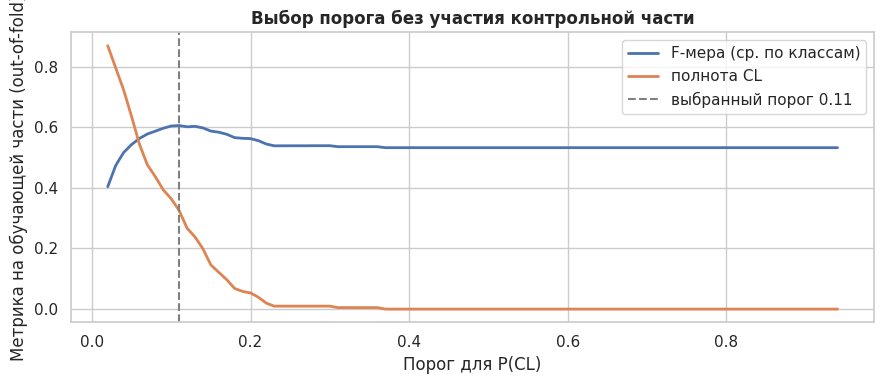

In [13]:
classes = list(final_model.classes_)
i_cl = classes.index('CL')
other_idx = [i for i, c in enumerate(classes) if c != 'CL']


def apply_threshold(proba, threshold):
    # CL, если вероятность CL выше порога, иначе более вероятный из остальных классов.
    fallback = np.array(classes)[other_idx][proba[:, other_idx].argmax(axis=1)]
    return np.where(proba[:, i_cl] > threshold, 'CL', fallback)


oof_proba = cross_val_predict(final_model, X_tr, y_tr, cv=CV,
                              method='predict_proba', n_jobs=-1)
thresholds = np.arange(0.02, 0.95, 0.01)
oof_f1 = [f1_score(y_tr, apply_threshold(oof_proba, t), average='macro') for t in thresholds]
oof_recall = [recall_score(y_tr, apply_threshold(oof_proba, t), labels=['CL'],
                           average=None)[0] for t in thresholds]
best_threshold = thresholds[int(np.argmax(oof_f1))]

print(f'Порог по out-of-fold вероятностям: {best_threshold:.2f}')
print(f'F-мера (ср. по классам) на обучающей части: {max(oof_f1):.4f}')

proba_te = final_model.predict_proba(X_te)
pred_threshold = apply_threshold(proba_te, best_threshold)
threshold_row = {
    'вариант': f'полином 22, порог CL = {best_threshold:.2f}',
    'доля верных ответов': accuracy_score(y_te, pred_threshold),
    'ср. доля верных по классам': balanced_accuracy_score(y_te, pred_threshold),
    'F-мера (ср. по классам)': f1_score(y_te, pred_threshold, average='macro'),
    'лог-потеря': final_row['лог-потеря'],
    'полнота CL': recall_score(y_te, pred_threshold, labels=['CL'], average=None)[0],
}
display(pd.DataFrame([threshold_row]).set_index('вариант').round(4))
print('Предсказано CL:', int((pred_threshold == 'CL').sum()), 'из', len(y_te))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(thresholds, oof_f1, label='F-мера (ср. по классам)', lw=2)
ax.plot(thresholds, oof_recall, label='полнота CL', lw=2)
ax.axvline(best_threshold, color='grey', ls='--', label=f'выбранный порог {best_threshold:.2f}')
ax.set_xlabel('Порог для P(CL)')
ax.set_ylabel('Метрика на обучающей части (out-of-fold)')
ax.set_title('Выбор порога без участия контрольной части', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

### Вывод по финальной оценке

| Вариант | Доля верных ответов | Ср. по классам | F-мера (ср.) | Лог-потеря | Полнота CL |
|---|---|---|---|---|---|
| Базовая (стадия 3) | 0.7951 | 0.5316 | 0.5322 | 0.5438 | 0.0145 |
| Полином + L1 (стадия 4) | 0.8022 | 0.5378 | 0.5309 | 0.5296 | 0.0000 |
| Полином + L1, 22 признака | **0.8037** | **0.5381** | **0.5316** | **0.5180** | 0.0000 |

Модель на 22 признаках улучшила все четыре «общие» метрики относительно стадии 4:
доля верных ответов выросла на 0.0015, лог-потеря упала на 0.0116. Относительно базовой
модели стадии 3 выигрыш заметнее: лог-потеря ниже на 0.0258.

Полнота `CL` при стандартном правиле равна нулю, как и у всех регуляризованных вариантов
стадии 4: порог 0.5 для класса, составляющего 3.5 % данных, недостижим.

Порог, выбранный по out-of-fold вероятностям обучающей части, — **0.11**. На контрольной
части он даёт:

| Метрика | Значение |
|---|---|
| Доля верных ответов | 0.7850 |
| Ср. доля верных по классам | 0.6033 |
| F-мера (ср. по классам) | **0.5952** |
| Полнота CL | **0.2609** (18 пациентов из 69) |
| Предсказано CL | 103 из 1 977 |

F-мера 0.5952 практически совпадает с лучшим результатом стадии 4 (0.5954) — при том,
что порог здесь выбран на другом наборе признаков и другой модели. Это хороший признак:
результат воспроизводится, а не является случайной удачей одного подбора.

Полнота `CL` 0.2609 ниже, чем 0.3913 у варианта «порог 0.07» из стадии 4, но там порог
подбирался прямо по контрольной части. Здесь порог выбран честно, без участия теста,
и именно это значение следует считать реальным.

## **10. Выводы**

### Что проверяли и что получили

| Вопрос | Ответ | Числа |
|---|---|---|
| Помогают ли клинические пороги? | Почти нет | прирост полинома 0.0005 |
| Помогают ли медицинские отношения? | Да, линейной модели | 0.5132 → 0.5067 |
| Нужен ли `log1p` при `RobustScaler`? | Да, обязательно | 0.4968 против 0.5057 |
| Вредно ли масштабировать бинарные? | Нет, но бесполезно | 0.4967 против 0.4968 |
| Какое масштабирование лучше? | `RobustScaler` | 0.4968 против 0.5868 без него |
| Обходят ли сплайны полином? | Нет | 0.5069 против 0.4968 |

### Главные выводы

1. **Отношения показателей — единственный существенный вклад из новых признаков.**
   Пара «билирубин к альбумину» и «возраст к тромбоцитам» дала линейной модели 0.0065,
   остальные пять признаков — 0.0003. Полиномиальные признаки не умеют делить,
   поэтому это единственный способ дать модели пропорции.

2. **Полиномиальная модель почти не нуждается в ручных признаках.** Прирост 0.0013
   меньше разброса между блоками (0.0173). Вторая степень уже содержит произведения,
   и они заменяют значительную часть ручной работы.

3. **Логарифмирование и устойчивое масштабирование не дублируют друг друга.**
   Разница 0.0089 в пользу логарифма — самое крупное улучшение на этой стадии.
   Масштабирование меняет единицы, логарифм меняет форму зависимости.

4. **Масштабирование критично, и выбор способа имеет значение.** Без него полиномиальная
   модель теряет 0.0900 лог-потери и перестаёт сходиться; `MinMaxScaler` почти так же плох
   (0.5180), потому что зависит от крайних значений. `StandardScaler` и `RobustScaler`
   равноценны по метрике, но `RobustScaler` устойчивее к новым выбросам.

5. **Коэффициенты без масштабирования не интерпретируются.** Максимальный коэффициент
   0.0010 при признаках в миллионах — это не «слабый эффект», а следствие единиц измерения.
   Сравнивать важность признаков можно только после приведения к общему масштабу.

6. **Сплайны — компромисс, а не улучшение.** Они в восемь раз компактнее (34 столбца
   против 275) и дают чуть меньший разброс, но проигрывают 0.0101 по средней лог-потере,
   потому что не создают взаимодействий между признаками.

### Итоговая модель

Пайплайн: `ColumnTransformer` (бинарные — как есть, числовые — `RobustScaler`) →
`PolynomialFeatures(degree=2)` → `LogisticRegression(saga, l1_ratio=1.0, C=0.1)`
на 22 признаках.

На контрольной части: доля верных ответов **0.8037**, F-мера **0.5316**,
лог-потеря **0.5180** — лучший результат по лог-потере за все стадии.
С порогом `CL = 0.11`, выбранным по out-of-fold вероятностям, F-мера поднимается
до **0.5952**, полнота `CL` — до **0.2609**.

### Ограничения

- Все приросты, кроме логарифмирования и масштабирования, лежат в пределах разброса
  между разбиениями. Клинические признаки не «сломали» задачу, но и не решили её.
- Семь новых признаков получены из тех же пятнадцати показателей, а не из новых
  измерений. Принципиально новой информации в них нет.
- Пороги взяты из общей клинической практики, а не подобраны под этот набор.
  Их ценность в интерпретируемости, а не в максимуме метрики.
- Оценка по-прежнему на одном разбиении 75/25; разброс такой оценки измерен в стадии 6
  и составляет 0.0458 по лог-потере.

### Глоссарий терминов

| Термин | Что означает | Зачем нужен здесь |
|---|---|---|
| **Клинический порог** | Граница показателя, после которой меняется трактовка | Даёт модели «ступеньку», которую линейная формула не построит сама |
| **Бинарный признак** | Столбец только из 0 и 1 | Компактная запись «значение перешло границу» |
| **Индекс-отношение** | Признак вида `A / B` | Полиномы дают произведения, но не отношения |
| **APRI** | `(AST / 40) / тромбоциты × 100` — маркер фиброза | Стандартный клинический индекс, известный врачу |
| **`RobustScaler`** | Вычитает медиану, делит на межквартильный размах | Устойчив к выбросам: смотрит на середину распределения |
| **`MinMaxScaler`** | Сжимает значения в отрезок от 0 до 1 | Чувствителен к крайним значениям |
| **`StandardScaler`** | Вычитает среднее, делит на стандартное отклонение | Классический вариант, чувствителен к выбросам |
| **`passthrough`** | Пропустить столбцы без преобразования | Бинарные признаки не нужно масштабировать |
| **`SplineTransformer`** | Кусочно-гладкие кривые вместо одного полинома | Устойчивее полинома на краях диапазона |
| **`PolynomialFeatures`** | Строит квадраты и произведения столбцов | Даёт модели нелинейность, но не отношения |
| **Абляция** | Поочерёдное добавление или удаление частей | Показывает вклад каждой группы признаков |
| **Out-of-fold вероятность** | Предсказание для строки моделью, не видевшей её | Честный выбор порога без участия теста |
| **Лог-потеря** | Мера качества вероятностей | Основной критерий сравнения вариантов |
| **Полнота CL** | Доля найденных пациентов с трансплантацией | Показывает, работает ли модель с редким классом |